# 图文视觉问答 VQA v2 小规模实验

本 Notebook 使用 VQA v2 官方训练/验证标注和 COCO 2014 图片，完成短答案分类。
所有数值和展示案例由下列代码运行生成。首版是规模受控的 pilot，后续可在配置中扩大样本数。

**研究问题**：同样的分类头只看问题与同时看问题、图片相比，准确率如何变化？
在冻结 CLIP 编码器之后，进一步微调视觉编码器最后一层是否改善结果？

数据：https://visualqa.org/download ；图片：https://cocodataset.org/ ；
模型与实现：https://github.com/openai/CLIP 。请在使用数据和预训练权重时遵守各自许可。


In [1]:
from __future__ import annotations

import base64
import copy
import hashlib
import json
import math
import os
import platform
import random
import statistics
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset

cwd = Path.cwd()
ROOT = next((path for path in (cwd, *cwd.parents, cwd / "vqa_project")
             if (path / "scripts" / "prepare_data.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open the notebook from the VQA repository")
os.chdir(ROOT)
sys.path[:0] = [str(ROOT / "vendor" / "python"), str(ROOT / "vendor" / "CLIP-main"),
                str(ROOT / "scripts")]
import clip
from prepare_data import build_manifest, MANIFEST, IMAGES, FAMILIES, VOCAB_SIZES

SEED = 42
TRAIN_PER_TYPE = 800
EVAL_PER_TYPE = 80
TOP_K = sum(VOCAB_SIZES.values())
HEAD_EPOCHS = 10
CONTINUE_EPOCHS = 2
FEATURE_SCALE = math.sqrt(512)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

def show_saved_image(filename):
    """Show saved figures in Jupyter; the local runner embeds them itself."""
    try:
        from IPython.display import Image as NotebookImage, display
    except ImportError:
        return
    display(NotebookImage(filename=str(RESULTS / filename)))

random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)
print("Python:", sys.version.split()[0], "PyTorch:", torch.__version__)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("Seed:", SEED)


Python: 3.11.0rc2 PyTorch: 2.9.0+cu128
Device: cuda NVIDIA GeForce RTX 4060 Laptop GPU
Seed: 42


## 1 数据与划分

按问题文本前缀区分是非、数量、颜色、动物类别四类；是非/动物还使用官方
`answer_type` 排除不符合该任务的题。每类从官方 train 抽 800 题；
从官方 val 先按图片 ID 划为互不重叠的 dev/test 图片池，再分别每类各抽 80 题。
问题类型均衡是本 pilot 的采样设定，
因此结果不能直接当作完整 VQA v2 基准成绩。标签取 10 个人工答案中的众数
`multiple_choice_answer`，评价指标为此标签上的分类 Exact Match Accuracy。

每种问题类型的答案词表只根据抽取的训练集建立，分别保留 2、11、12、10 类。
分类时仅考虑该问题类型的合法答案。训练时丢弃众数答案不在词表中的题；
dev/test 保留这些题并计为错误，同时报告词表覆盖率。


In [2]:
manifest = build_manifest(TRAIN_PER_TYPE, EVAL_PER_TYPE, VOCAB_SIZES, SEED)
rows = manifest["rows"]
splits = {name: [row for row in rows if row["split"] == name]
          for name in ("train", "dev", "test")}
vocabulary = manifest["vocabulary"]
allowed_ids = manifest["allowed_ids"]
assert len(vocabulary) == TOP_K
assert not ({r["image_id"] for r in splits["dev"]} &
            {r["image_id"] for r in splits["test"]})
assert not ({r["image_id"] for r in splits["train"]} &
            {r["image_id"] for r in splits["dev"] + splits["test"]})
missing_images = [r["image"] for r in rows if not (IMAGES / r["image"]).is_file()]
if missing_images:
    raise FileNotFoundError(
        f"Missing {len(set(missing_images))} COCO images. "
        "Run: python scripts/prepare_data.py --download-images")
for name in ("train", "dev", "test"):
    s = manifest["stats"][name]
    print(f"{name:5s} questions={s['questions']:4d} images={s['images']:4d} "
          f"vocab_coverage={s['majority_answer_coverage']:.1%} families={s['question_families']}")
for family in FAMILIES:
    print(f"{family:6s} answers:", [vocabulary[i] for i in allowed_ids[family]])


train questions=3200 images=3087 vocab_coverage=90.4% families={'count': 800, 'yes/no': 800, 'animal': 800, 'color': 800}
dev   questions= 320 images= 314 vocab_coverage=90.9% families={'animal': 80, 'count': 80, 'color': 80, 'yes/no': 80}
test  questions= 320 images= 317 vocab_coverage=87.8% families={'animal': 80, 'color': 80, 'count': 80, 'yes/no': 80}
yes/no answers: ['yes', 'no']
count  answers: ['1', '2', '3', '0', '4', '6', '5', '8', '7', '10', '12']
color  answers: ['white', 'black', 'blue', 'red', 'brown', 'green', 'yellow', 'gray', 'pink', 'purple', 'orange', 'silver']
animal answers: ['dog', 'cat', 'horse', 'elephant', 'giraffe', 'cow', 'zebra', 'bear', 'sheep', 'bird']


Saved results/data_distribution.png


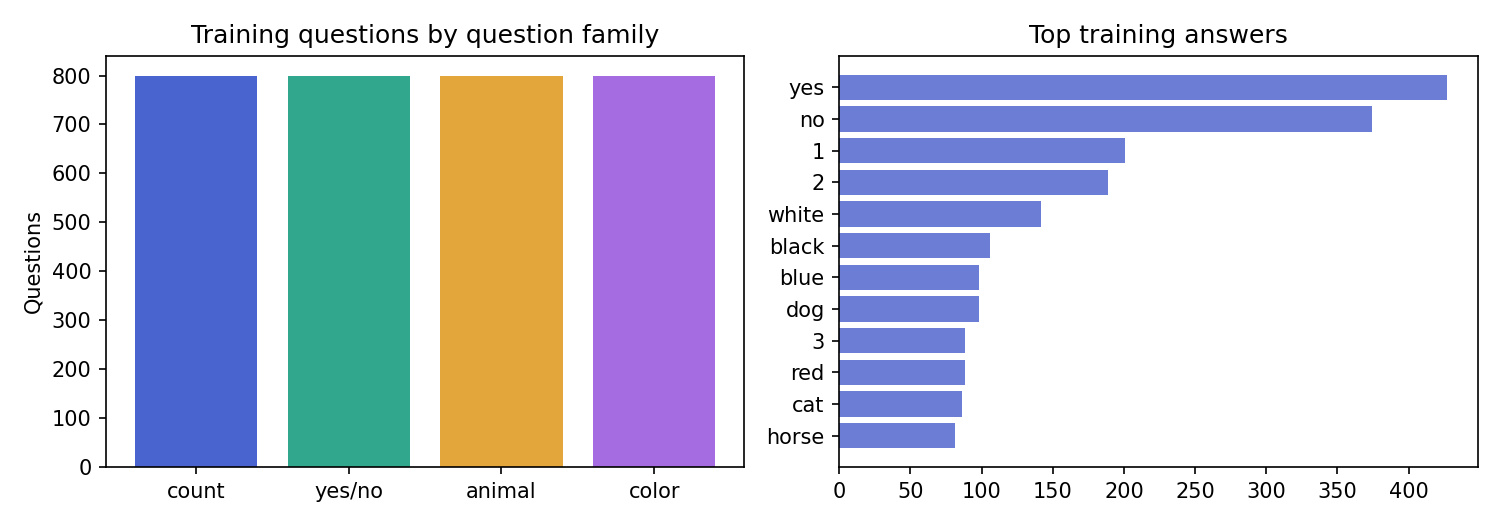

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
type_counts = manifest["stats"]["train"]["question_families"]
axes[0].bar(list(type_counts), list(type_counts.values()),
            color=["#4964ce", "#31a88e", "#e3a63b", "#a56be1"])
axes[0].set_title("Training questions by question family")
axes[0].set_ylabel("Questions")
counts = Counter(r["answer"] for r in splits["train"])
top = counts.most_common(12)
axes[1].barh([x[0] for x in top][::-1], [x[1] for x in top][::-1], color="#6b7dd4")
axes[1].set_title("Top training answers")
fig.tight_layout()
fig.savefig(RESULTS / "data_distribution.png", dpi=150)
plt.close(fig)
print("Saved results/data_distribution.png")
show_saved_image("data_distribution.png")


## 2 预训练 CLIP 特征与模型

图像和问题分别由 OpenAI CLIP ViT-B/32 编码为 512 维向量。
仅文本与图文模型使用同一个 2048→256→35 分类头：仅文本输入为
`[q,0,0,0]`，图文输入为 `[q,v,q×v,|q−v|]`。
编码向量先归一化，再乘 √512，使各分量保持可训练的数值尺度。
两种输入的分类头结构、训练数据、epoch 和优化器相同。
冻结编码器时，每个唯一图片和问题只编码一次并缓存。


In [4]:
weight_path = ROOT / "data" / "raw" / "ViT-B-32.pt"
if not weight_path.is_file():
    raise FileNotFoundError("Download official OpenAI ViT-B-32.pt; see README.md")
expected_sha = "40d365715913c9da98579312b702a82c18be219cc2a73407c4526f58eba950af"
actual_sha = hashlib.sha256(weight_path.read_bytes()).hexdigest()
assert actual_sha == expected_sha, "CLIP weight SHA256 mismatch"
clip_model, preprocess = clip.load(str(weight_path), device=DEVICE, jit=False)
clip_model = clip_model.float().eval()
for parameter in clip_model.parameters():
    parameter.requires_grad_(False)
print("CLIP loaded; total parameters:", f"{sum(p.numel() for p in clip_model.parameters()):,}")

class ImageFeatureDataset(Dataset):
    def __init__(self, paths):
        self.paths = paths
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, index):
        name = self.paths[index]
        with Image.open(IMAGES / name) as image:
            tensor = preprocess(image.convert("RGB"))
        return name, tensor

manifest_sha = hashlib.sha256(MANIFEST.read_bytes()).hexdigest()[:12]
feature_file = RESULTS / f"features_{manifest_sha}.pt"
if feature_file.is_file():
    feature_cache = torch.load(feature_file, map_location="cpu", weights_only=True)
else:
    image_paths = sorted({row["image"] for row in rows})
    image_features = {}
    image_loader = DataLoader(ImageFeatureDataset(image_paths), batch_size=64, shuffle=False,
                              num_workers=0)
    start = time.perf_counter()
    with torch.inference_mode():
        for names, pixels in image_loader:
            encoded = (F.normalize(clip_model.encode_image(pixels.to(DEVICE)).float(), dim=-1)
                       * FEATURE_SCALE).cpu()
            for name, vector in zip(names, encoded):
                image_features[name] = vector
    print(f"Encoded {len(image_features)} unique images in {time.perf_counter()-start:.1f}s")

    text_features = {}
    start = time.perf_counter()
    with torch.inference_mode():
        for offset in range(0, len(rows), 128):
            group = rows[offset:offset + 128]
            tokens = clip.tokenize([row["question"] for row in group], truncate=True).to(DEVICE)
            encoded = (F.normalize(clip_model.encode_text(tokens).float(), dim=-1)
                       * FEATURE_SCALE).cpu()
            for row, vector in zip(group, encoded):
                text_features[row["question_id"]] = vector
    print(f"Encoded {len(text_features)} questions in {time.perf_counter()-start:.1f}s")
    feature_cache = {"images": image_features, "questions": text_features}
    torch.save(feature_cache, feature_file)
print("Feature cache:", feature_file.name)

def make_vectors(examples, use_image):
    vectors = []
    for row in examples:
        q = feature_cache["questions"][row["question_id"]]
        if use_image:
            v = feature_cache["images"][row["image"]]
            vectors.append(torch.cat((q, v, q * v, (q - v).abs())))
        else:
            vectors.append(torch.cat((q, torch.zeros_like(q),
                                      torch.zeros_like(q), torch.zeros_like(q))))
    return torch.stack(vectors)

train_rows = [row for row in splits["train"] if row["label_id"] >= 0]
vectors = {mode: {name: make_vectors(split_rows, use_image=(mode == "fusion"))
                  for name, split_rows in splits.items()}
           for mode in ("text", "fusion")}
labels = {name: torch.tensor([row["label_id"] for row in split_rows], dtype=torch.long)
          for name, split_rows in splits.items()}
train_mask = labels["train"] >= 0

def answer_mask(examples):
    mask = torch.full((len(examples), TOP_K), -1e4)
    for index, row in enumerate(examples):
        mask[index, allowed_ids[row["question_family"]]] = 0.0
    return mask

answer_masks = {name: answer_mask(split_rows) for name, split_rows in splits.items()}

class AnswerHead(nn.Module):
    def __init__(self, classes):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2048, 256), nn.ReLU(),
                                 nn.Dropout(0.2), nn.Linear(256, classes))
    def forward(self, features):
        return self.net(features)

def cached_logits(head, x, mask, batch_size=256):
    head.eval()
    outputs = []
    with torch.inference_mode():
        for batch in x.split(batch_size):
            outputs.append(head(batch.to(DEVICE)).cpu())
    return torch.cat(outputs) + mask

def accuracy(logits, y):
    return (logits.argmax(dim=1) == y).float().mean().item()

def train_cached_head(mode, epochs, initial_state=None, lr=1e-3,
                      batch_size=64, select_best=True):
    if initial_state is None:
        torch.manual_seed(SEED + 11)  # identical head initialization for text and fusion
    head = AnswerHead(TOP_K).to(DEVICE)
    if initial_state is not None:
        head.load_state_dict(initial_state)
    optimizer = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=0.01)
    x_train = vectors[mode]["train"][train_mask]
    y_train = labels["train"][train_mask]
    mask_train = answer_masks["train"][train_mask]
    x_dev, y_dev = vectors[mode]["dev"], labels["dev"]
    loader = DataLoader(TensorDataset(x_train, y_train, mask_train), batch_size=batch_size,
                        shuffle=True, generator=torch.Generator().manual_seed(SEED))
    history = []
    best_state = copy.deepcopy(head.state_dict())
    best_dev = accuracy(cached_logits(head, x_dev, answer_masks["dev"]), y_dev)
    for epoch in range(1, epochs + 1):
        head.train()
        total_loss = 0.0
        for x, y, mask in loader:
            x, y, mask = x.to(DEVICE), y.to(DEVICE), mask.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(head(x) + mask, y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)
        dev_acc = accuracy(cached_logits(head, x_dev, answer_masks["dev"]), y_dev)
        history.append({"epoch": epoch, "train_loss": total_loss / len(y_train),
                        "dev_accuracy": dev_acc})
        if select_best and dev_acc >= best_dev:
            best_dev = dev_acc
            best_state = copy.deepcopy(head.state_dict())
        print(f"{mode:6s} epoch={epoch} loss={history[-1]['train_loss']:.4f} dev_acc={dev_acc:.3f}")
    if select_best:
        head.load_state_dict(best_state)
        return head, history, best_dev
    return head, history, history[-1]["dev_accuracy"]


CLIP loaded; total parameters: 151,277,313
Feature cache: features_a40fb156ccc4.pt


In [5]:
text_head, text_history, text_dev = train_cached_head("text", HEAD_EPOCHS)
fusion_head, fusion_history, fusion_dev = train_cached_head("fusion", HEAD_EPOCHS)
frozen_head, frozen_history, frozen_dev = train_cached_head(
    "fusion", CONTINUE_EPOCHS, copy.deepcopy(fusion_head.state_dict()), lr=3e-4,
    batch_size=16, select_best=False)
print(f"Best dev: text={text_dev:.3f}, fusion={fusion_dev:.3f}, frozen continuation={frozen_dev:.3f}")


text   epoch=1 loss=1.7735 dev_acc=0.297
text   epoch=2 loss=1.6681 dev_acc=0.269
text   epoch=3 loss=1.6051 dev_acc=0.344
text   epoch=4 loss=1.5455 dev_acc=0.291
text   epoch=5 loss=1.4911 dev_acc=0.303
text   epoch=6 loss=1.4407 dev_acc=0.297
text   epoch=7 loss=1.3818 dev_acc=0.322
text   epoch=8 loss=1.3284 dev_acc=0.294
text   epoch=9 loss=1.2725 dev_acc=0.284
text   epoch=10 loss=1.2339 dev_acc=0.253
fusion epoch=1 loss=1.6297 dev_acc=0.363
fusion epoch=2 loss=1.2866 dev_acc=0.431
fusion epoch=3 loss=1.0823 dev_acc=0.481
fusion epoch=4 loss=0.9287 dev_acc=0.472
fusion epoch=5 loss=0.7773 dev_acc=0.466
fusion epoch=6 loss=0.6487 dev_acc=0.488
fusion epoch=7 loss=0.5268 dev_acc=0.469
fusion epoch=8 loss=0.4197 dev_acc=0.422
fusion epoch=9 loss=0.3523 dev_acc=0.450
fusion epoch=10 loss=0.2912 dev_acc=0.453
fusion epoch=1 loss=0.5227 dev_acc=0.450
fusion epoch=2 loss=0.4337 dev_acc=0.466
Best dev: text=0.344, fusion=0.488, frozen continuation=0.466


## 3 局部微调视觉编码器

冻结对照和微调组都从相同的 10-epoch 图文分类头出发，再各训练 2 epoch。
微调组只解冻 CLIP 视觉 Transformer 的最后一个 block、后层归一化和投影参数；
文本编码器始终冻结。这样能够分离“增加训练轮次”和“解冻骨干”的影响。


In [6]:
class LiveDataset(Dataset):
    def __init__(self, examples):
        self.examples = examples
    def __len__(self):
        return len(self.examples)
    def __getitem__(self, index):
        row = self.examples[index]
        with Image.open(IMAGES / row["image"]) as image:
            pixels = preprocess(image.convert("RGB"))
        q = feature_cache["questions"][row["question_id"]]
        return pixels, q, row["label_id"], answer_mask([row])[0]

def live_logits(visual, head, examples, batch_size=32):
    visual.eval()
    head.eval()
    output = []
    loader = DataLoader(LiveDataset(examples), batch_size=batch_size,
                        shuffle=False, num_workers=0)
    with torch.inference_mode():
        for pixels, q, _, mask in loader:
            pixels, q = pixels.to(DEVICE), q.to(DEVICE)
            v = F.normalize(visual(pixels).float(), dim=-1) * FEATURE_SCALE
            fused = torch.cat((q, v, q * v, (q - v).abs()), dim=-1)
            output.append(head(fused).cpu() + mask)
    return torch.cat(output)

base_visual_state = {name: value.cpu().clone()
                     for name, value in clip_model.visual.state_dict().items()}
visual = clip_model.visual
for parameter in visual.parameters():
    parameter.requires_grad_(False)
for parameter in visual.transformer.resblocks[-1].parameters():
    parameter.requires_grad_(True)
for parameter in visual.ln_post.parameters():
    parameter.requires_grad_(True)
visual.proj.requires_grad_(True)
finetune_head = copy.deepcopy(fusion_head).to(DEVICE)
finetune_optimizer = torch.optim.AdamW([
    {"params": [p for p in visual.parameters() if p.requires_grad], "lr": 1e-5},
    {"params": finetune_head.parameters(), "lr": 3e-4},
], weight_decay=0.01)
live_train = DataLoader(LiveDataset(train_rows), batch_size=16, shuffle=True,
                        num_workers=0, generator=torch.Generator().manual_seed(SEED))
finetune_history = []
for epoch in range(1, CONTINUE_EPOCHS + 1):
    visual.train()
    finetune_head.train()
    total_loss = 0.0
    start = time.perf_counter()
    for pixels, q, y, mask in live_train:
        pixels, q, y, mask = (pixels.to(DEVICE), q.to(DEVICE),
                              y.to(DEVICE), mask.to(DEVICE))
        finetune_optimizer.zero_grad(set_to_none=True)
        v = F.normalize(visual(pixels).float(), dim=-1) * FEATURE_SCALE
        fused = torch.cat((q, v, q * v, (q - v).abs()), dim=-1)
        loss = F.cross_entropy(finetune_head(fused) + mask, y)
        loss.backward()
        finetune_optimizer.step()
        total_loss += loss.item() * len(y)
    dev_logits = live_logits(visual, finetune_head, splits["dev"])
    dev_acc = accuracy(dev_logits, labels["dev"])
    finetune_history.append({"epoch": HEAD_EPOCHS + epoch,
                             "train_loss": total_loss / len(train_rows),
                             "dev_accuracy": dev_acc,
                             "seconds": time.perf_counter() - start})
    print(f"finetune epoch={epoch} loss={finetune_history[-1]['train_loss']:.4f} "
          f"dev_acc={dev_acc:.3f} seconds={finetune_history[-1]['seconds']:.1f}")
finetune_dev = finetune_history[-1]["dev_accuracy"]
finetune_visual = {name: p.detach().cpu().clone() for name, p in visual.named_parameters()
                   if p.requires_grad}
torch.save({"visual_delta": finetune_visual, "head": finetune_head.state_dict(),
            "vocabulary": vocabulary}, RESULTS / "finetuned_layers.pt")
print(f"Fine-tuned dev accuracy after {CONTINUE_EPOCHS} epochs: {finetune_dev:.3f}")


finetune epoch=1 loss=0.5231 dev_acc=0.453 seconds=85.5
finetune epoch=2 loss=0.3203 dev_acc=0.459 seconds=52.7
Fine-tuned dev accuracy after 2 epochs: 0.459


## 4 评估、模型复杂度和耗时

测试集只在训练与模型选择完成后评估。分类 Accuracy 的分母包括 OOV 样本，
因此本实验的分类准确率上限由答案词表覆盖率约束。
MACs 统计 CLIP 图像/文本 Transformer 的卷积、线性层和注意力矩阵乘法，
以及分类头线性层；不含 LayerNorm、激活、预处理、磁盘读取等操作。
耗时是预处理完成后单样本 GPU/CPU 前向传播，包含图像和文本编码与分类头。


Test classification exact-match accuracy, including OOV as incorrect:
majority     overall=0.234 yes/no=0.438 count=0.275 color=0.138 animal=0.087
text         overall=0.291 yes/no=0.562 count=0.250 color=0.250 animal=0.100
fusion       overall=0.434 yes/no=0.550 count=0.275 color=0.300 animal=0.613
frozen_cont  overall=0.447 yes/no=0.600 count=0.237 color=0.362 animal=0.588
finetune     overall=0.434 yes/no=0.575 count=0.212 color=0.325 animal=0.625
Selected for HTML by dev accuracy: fusion
Params: total=151,810,852, head_trainable=533,539, finetune_trainable=8,016,163
Approx. MACs: text_only=2.98G, fusion=7.39G at 224x224 image, 77 text tokens
Selected model forward latency median: 33.2 ms (batch=1, excludes preprocessing)
Saved results/summary.json and results/training_curves.png


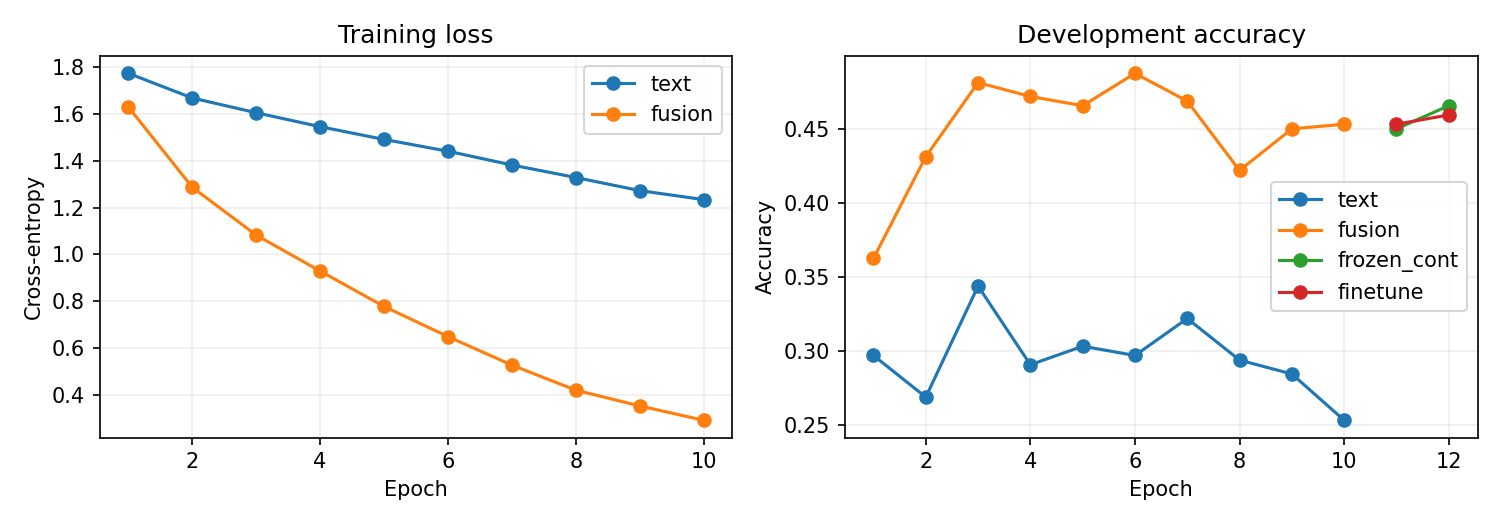

In [7]:
test_logits = {
    "text": cached_logits(text_head, vectors["text"]["test"], answer_masks["test"]),
    "fusion": cached_logits(fusion_head, vectors["fusion"]["test"], answer_masks["test"]),
    "frozen_cont": cached_logits(frozen_head, vectors["fusion"]["test"], answer_masks["test"]),
    "finetune": live_logits(visual, finetune_head, splits["test"]),
}
dev_scores = {"text": text_dev, "fusion": fusion_dev,
              "frozen_cont": frozen_dev, "finetune": finetune_dev}
selected_model = max(("fusion", "frozen_cont", "finetune"),
                     key=lambda name: dev_scores[name])

def score_by_type(logits, examples):
    predicted = logits.argmax(dim=1).tolist()
    overall = sum(pred == row["label_id"] for pred, row in zip(predicted, examples)) / len(examples)
    groups = {}
    for answer_type in FAMILIES:
        pairs = [(pred, row) for pred, row in zip(predicted, examples)
                 if row["question_family"] == answer_type]
        groups[answer_type] = sum(pred == row["label_id"] for pred, row in pairs) / len(pairs)
    return {"overall": overall, "by_type": groups}

scores = {name: score_by_type(logits, splits["test"])
          for name, logits in test_logits.items()}
majority_by_family = {family: Counter(r["label_id"] for r in train_rows
                                      if r["question_family"] == family).most_common(1)[0][0]
                      for family in FAMILIES}
majority_logits = answer_masks["test"].clone()
for index, row in enumerate(splits["test"]):
    majority_logits[index, majority_by_family[row["question_family"]]] = 1
scores["majority"] = score_by_type(majority_logits, splits["test"])
print("Test classification exact-match accuracy, including OOV as incorrect:")
for name in ("majority", "text", "fusion", "frozen_cont", "finetune"):
    s = scores[name]
    print(f"{name:12s} overall={s['overall']:.3f} "
          f"yes/no={s['by_type']['yes/no']:.3f} "
          f"count={s['by_type']['count']:.3f} "
          f"color={s['by_type']['color']:.3f} "
          f"animal={s['by_type']['animal']:.3f}")
print("Selected for HTML by dev accuracy:", selected_model)

def clip_macs(model):
    visual = model.visual
    patch = visual.conv1.kernel_size[0]
    resolution = visual.input_resolution
    n_image = (resolution // patch) ** 2 + 1
    d_image = visual.conv1.out_channels
    image_layers = len(visual.transformer.resblocks)
    conv = (resolution // patch) ** 2 * d_image * 3 * patch * patch
    image_block = 12 * n_image * d_image * d_image + 2 * n_image * n_image * d_image
    image_macs = conv + image_layers * image_block + d_image * visual.proj.shape[1]
    n_text = model.context_length
    d_text = model.token_embedding.embedding_dim
    text_layers = len(model.transformer.resblocks)
    text_block = 12 * n_text * d_text * d_text + 2 * n_text * n_text * d_text
    text_macs = text_layers * text_block + d_text * model.text_projection.shape[1]
    head_macs = 2048 * 256 + 256 * TOP_K
    return {"image": int(image_macs), "text": int(text_macs),
            "head": int(head_macs), "text_only": int(text_macs + head_macs),
            "fusion": int(image_macs + text_macs + head_macs)}

macs = clip_macs(clip_model)
head_params = sum(p.numel() for p in fusion_head.parameters())
visual_trainable = sum(p.numel() for p in visual.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in clip_model.parameters()) + head_params
print(f"Params: total={total_params:,}, head_trainable={head_params:,}, "
      f"finetune_trainable={head_params + visual_trainable:,}")
print(f"Approx. MACs: text_only={macs['text_only']/1e9:.2f}G, "
      f"fusion={macs['fusion']/1e9:.2f}G at 224x224 image, 77 text tokens")

if selected_model != "finetune":
    visual.load_state_dict(base_visual_state)
selected_head = {"fusion": fusion_head, "frozen_cont": frozen_head,
                 "finetune": finetune_head}[selected_model]
sample = splits["test"][0]
with Image.open(IMAGES / sample["image"]) as image:
    sample_pixels = preprocess(image.convert("RGB")).unsqueeze(0).to(DEVICE)
sample_tokens = clip.tokenize([sample["question"]], truncate=True).to(DEVICE)

def forward_once():
    with torch.inference_mode():
        q = F.normalize(clip_model.encode_text(sample_tokens).float(), dim=-1) * FEATURE_SCALE
        v = F.normalize(visual(sample_pixels).float(), dim=-1) * FEATURE_SCALE
        return selected_head(torch.cat((q, v, q * v, (q - v).abs()), dim=-1))

for _ in range(5):
    forward_once()
if DEVICE == "cuda":
    torch.cuda.synchronize()
times = []
for _ in range(20):
    start = time.perf_counter()
    forward_once()
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    times.append((time.perf_counter() - start) * 1000)
latency_ms = statistics.median(times)
print(f"Selected model forward latency median: {latency_ms:.1f} ms (batch=1, excludes preprocessing)")

all_histories = {"text": text_history, "fusion": fusion_history,
                 "frozen_cont": frozen_history, "finetune": finetune_history}
(RESULTS / "histories.json").write_text(json.dumps(all_histories, indent=2), encoding="utf-8")
summary = {"task": "VQA v2 pilot, classification exact match",
           "seed": SEED, "train_per_type": TRAIN_PER_TYPE,
           "eval_per_type": EVAL_PER_TYPE, "top_k": TOP_K,
           "vocab_sizes": VOCAB_SIZES,
           "head_epochs": HEAD_EPOCHS, "continue_epochs": CONTINUE_EPOCHS,
           "vocab_coverage": {k: v["majority_answer_coverage"] for k,v in manifest["stats"].items()},
           "dev_accuracy": dev_scores, "test_scores": scores,
           "selected_model": selected_model, "total_params": total_params,
           "head_trainable_params": head_params,
           "finetune_trainable_params": head_params + visual_trainable,
           "macs": macs, "latency_ms_median": latency_ms,
           "device": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU",
           "python": platform.python_version(), "torch": torch.__version__}
(RESULTS / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for mode, history in (("text", text_history), ("fusion", fusion_history)):
    axes[0].plot([h["epoch"] for h in history], [h["train_loss"] for h in history],
                 marker="o", label=mode)
    axes[1].plot([h["epoch"] for h in history], [h["dev_accuracy"] for h in history],
                 marker="o", label=mode)
for mode, history in (("frozen_cont", frozen_history), ("finetune", finetune_history)):
    axes[1].plot([HEAD_EPOCHS + h["epoch"] if mode == "frozen_cont" else h["epoch"] for h in history],
                 [h["dev_accuracy"] for h in history], marker="o", label=mode)
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy", title="Training loss")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Development accuracy")
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "training_curves.png", dpi=150)
plt.close(fig)
print("Saved results/summary.json and results/training_curves.png")
show_saved_image("training_curves.png")


## 5 实际预测案例与 HTML 演示

按 dev 集准确率确定展示模型，然后从未参与训练的 test 集抽取真实正确与错误案例。
HTML 内嵌图片和预测数据，可离线打开；页面上的“置信度”是 softmax 分数，
尚未进行概率校准。由于词表封闭，任意新问题未必有可用答案，因此页面展示固定测试样例。


In [8]:
probabilities = {name: logits.softmax(dim=1) for name, logits in test_logits.items()}
prediction_rows = []
for i, row in enumerate(splits["test"]):
    record = {k: row[k] for k in ("question_id", "image_id", "question", "answer",
                                   "question_family", "image", "label_id")}
    record["models"] = {}
    for name, probs in probabilities.items():
        index = int(probs[i].argmax())
        record["models"][name] = {"answer": vocabulary[index],
                                  "confidence": round(float(probs[i, index]), 4),
                                  "correct": index == row["label_id"]}
    prediction_rows.append(record)
(RESULTS / "predictions.json").write_text(
    json.dumps(prediction_rows, ensure_ascii=False, indent=2), encoding="utf-8")

gallery = []
for answer_type in FAMILIES:
    group = [r for r in prediction_rows if r["question_family"] == answer_type]
    good = [r for r in group if r["models"][selected_model]["correct"]]
    bad = [r for r in group if not r["models"][selected_model]["correct"]]
    gallery.extend(good[:2] + bad[:2])
for record in gallery:
    record["image_data"] = "data:image/jpeg;base64," + base64.b64encode(
        (IMAGES / record["image"]).read_bytes()).decode("ascii")
demo_data = {"samples": gallery, "summary": summary}
demo_json = json.dumps(demo_data, ensure_ascii=False).replace("</", "<\\/")
html_template = (ROOT / "demo" / "demo_template.html").read_text(encoding="utf-8")
html = html_template.replace("__VQA_DATA__", demo_json)
(ROOT / "demo" / "demo.html").write_text(html, encoding="utf-8")
print(f"Wrote demo/demo.html with {len(gallery)} real held-out examples")
print("Selected model:", selected_model)
print("First example:", gallery[0]["question"], "->",
      gallery[0]["models"][selected_model]["answer"],
      f"({gallery[0]['models'][selected_model]['confidence']:.1%})")


Wrote demo.html with 16 real held-out examples
Selected model: fusion
First example: Is this person walking on water? -> no (85.2%)
